<a href="https://www.kaggle.com/code/quddusikashaf/roformer?scriptVersionId=293482784" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

## Data Processing

In [1]:
# Based on the paper: "A rotary transformer cross-subject model for continuous estimation of finger joints kinematics and a transfer learning approach for new subjects"
# Dataset: Ninapro DB2 (sEMG, 12 channels, 10 joint angles)
# Architecture: Conv1D -> RoPE -> Multi-Head Attention -> Add&Norm -> Feed Forward -> Add&Norm -> FC (10 angles)
# Requirements: Download Ninapro DB2 from https://ninapro.hevs.ch/ (registration required), process using https://github.com/increase24/Ninapro-dataset-processing
# Assume processed data: sEMG windows (12 x time_steps) and labels (10 joint angles)

# Install Dependencies
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install transformers datasets accelerate wandb tqdm numpy scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 11.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.5/47.5 MB 43.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 112.4 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 88.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 33.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 14.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 7.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━

In [2]:
import os
import numpy as np
import glob
import scipy.io as scio
from scipy.signal import butter, sosfiltfilt

import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import random


In [3]:
def mu_law_normalize(x, mu=255):
    """
    Apply μ-law companding to EMG data.
    Input x should be normalized to [-1,1].
    """
    return np.sign(x) * np.log1p(mu * np.abs(x)) / np.log1p(mu)

def bandpass_butterworth(emg, lowcut=5, highcut=500, fs=2000, order=4):
    """
    Apply a Butterworth bandpass filter to EMG data.
    
    Args:
    - emg: [time, channels] array
    - lowcut: Low frequency cutoff (Hz)
    - highcut: High frequency cutoff (Hz)
    - fs: Sampling rate (Hz)
    - order: Filter order
    
    Returns:
    - Filtered emg array
    """
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    sos = butter(order, [low, high], btype='band', output='sos')
    return sosfiltfilt(sos, emg, axis=0)

from scipy import signal
import numpy as np
import matplotlib.pyplot as plt

def apply_comb_filter(data, fs=2000, f0=50, Q=30):
    """
    Applies an IIR Comb Notch Filter to remove fundamental freq and harmonics.
    
    :param data: Input EMG data (Time x Channels) or (Time,)
    :param fs: Sampling frequency (Ninapro DB2 is usually 2000Hz)
    :param f0: Fundamental frequency to remove (50Hz for Europe/Asia, 60Hz for US)
    :param Q: Quality factor. Higher Q = narrower notch (preserves more EMG signal).
    """
    # Design the Comb Filter
    # ftype='notch' creates nulls at 0, f0, 2*f0, 3*f0...
    b, a = signal.iircomb(w0=f0, Q=Q, ftype='notch', fs=fs)
    
    # Apply filter along the time axis (axis 0 for your shape)
    filtered_data = signal.filtfilt(b, a, data, axis=0)
    
    return filtered_data

# --- Integration into your Pipeline ---
# Inside process_dataset_for_oneSubject:
# emg = apply_comb_filter(emg, fs=2000, f0=50, Q=30)
def lowpass_butterworth(emg, cutoff=450, fs=2000, order=4):
    """
    Apply a Butterworth low-pass filter to EMG data.
    
    Args:
    - emg: [time, channels] array
    - cutoff: Cutoff frequency (Hz)
    - fs: Sampling rate (Hz)
    - order: Filter order
    
    Returns:
    - Filtered emg array
    """
    nyq = 0.5 * fs
    high = cutoff / nyq
    sos = butter(order, high, btype='low', output='sos')
    return sosfiltfilt(sos, emg, axis=0)

def downsample_emg(emg, fs_original=2000, target_fs=1000):
    """
    Downsample EMG signals using decimation.
    
    Args:
    - emg: [time, channels] array
    - fs_original: Original sampling rate (Hz)
    - target_fs: Target sampling rate (Hz)
    
    Returns:
    - Downsampled emg array
    """
    down_factor = int(fs_original / target_fs)
    return decimate(emg, down_factor, axis=0)

In [4]:
def process_dataset_for_oneSubject(subject, window_size=400, stride=50, mu=255):
    print(f"Processing subject: {subject}")
    data_paths = sorted(glob.glob(f'/kaggle/input/ninapro-db2/{subject}/{subject}/*.mat'))
    
    emg_all, glove_all, restim_all = [], [], []
    for path in data_paths[:2]:  # use first two sessions
        data = scio.loadmat(path)
        emg_all.append(data['emg'])
        glove_all.append(data['glove'])
        restim_all.append(data['restimulus'])   # repetition labels
    
    emg = np.vstack(emg_all).astype(np.float32)
    glove = np.vstack(glove_all).astype(np.float32)
    restimulus = np.vstack(restim_all).astype(np.int32).squeeze()

    # --- EMG: Apply Butterworth filters ---
    # channels = [0,2,4,5,8,9,10,11]
    # emg = emg[:,channels]
    emg = bandpass_butterworth(emg)
    # emg = apply_comb_filter(emg)
    emg = abs(emg)

    # --- EMG: μ-law normalization ---
    emg = emg / (np.max(np.abs(emg), axis=0, keepdims=True) + 1e-8)
    emg = mu_law_normalize(emg, mu=mu)
    

    # --- Glove: Min-Max normalization [0,1] ---
    glove_min = np.min(glove, axis=0, keepdims=True)
    glove_max = np.max(glove, axis=0, keepdims=True)
    glove = (glove - glove_min) / (glove_max - glove_min + 1e-8)

    # 🔧 Keep only 10 glove joints
    cols = [1, 2, 4, 5, 7, 8, 11, 12, 15, 16]
    glove = glove[:, cols]
    glove_min = glove_min[:, cols]
    glove_max = glove_max[:, cols]    

    # --- Sliding window segmentation ---
    emg_windows, glove_windows, restim_windows = [], [], []
    for i in range(0, len(emg) - window_size, stride):
        emg_win = emg[i:i+window_size, :]
        glove_win = glove[i+window_size-1, :]
        restim_win = restimulus[i+window_size-1]  # label at last frame
        emg_windows.append(emg_win)
        glove_windows.append(glove_win)
        restim_windows.append(restim_win)

    emg_windows = np.array(emg_windows)
    glove_windows = np.array(glove_windows)
    restim_windows = np.array(restim_windows)

    # Save processed data
    output_dir = f"/kaggle/working/db2_processed/{subject}"
    os.makedirs(output_dir, exist_ok=True)
    np.savez(f"{output_dir}/data.npz", 
             sEMG=emg_windows, 
             angles=glove_windows, 
             restim=restim_windows)
    print(f"Saved {emg_windows.shape[0]} samples for {subject}")


In [5]:
base_path = '/kaggle/input/ninapro-db2'
subjects = sorted([folder for folder in os.listdir(base_path)])
for i, subject in enumerate(subjects[:3]):  # first 10 for testing
    process_dataset_for_oneSubject(subject)

# ----------------------------------------------------------
# # Example: first 15 subjects for training, last 5 for validation
# base_path = '/kaggle/input/ninapro-db2'
# subjects = sorted([folder for folder in os.listdir(base_path)])

# for subject in subjects[:10]:   # preprocess first 20 subjects
#     process_dataset_for_oneSubject(subject)
    
# train_subjects = subjects[:7]
# val_subjects   = subjects[7:10]

# train_files = [f"/kaggle/working/db2_processed/{s}/data.npz" for s in train_subjects]
# val_files   = [f"/kaggle/working/db2_processed/{s}/data.npz" for s in val_subjects]



Processing subject: DB2_s1
Saved 87225 samples for DB2_s1
Processing subject: DB2_s10
Saved 87069 samples for DB2_s10
Processing subject: DB2_s11
Saved 86987 samples for DB2_s11


In [6]:

# class NinaproDataset(Dataset):
#     def __init__(self, npz_files, split='train', split_ratio=0.8):
#         # Load all subjects and concatenate
#         sEMG_all, angles_all = [], []
#         for f in npz_files:
#             data = np.load(f,mmap_mode='r')
#             sEMG_all.append(data['sEMG'])
#             angles_all.append(data['angles'])
#         self.sEMG = np.concatenate(sEMG_all, axis=0)
#         self.angles = np.concatenate(angles_all, axis=0)

#         # Split
#         split_idx = int(split_ratio * len(self.sEMG))
#         if split == 'train':
#             self.sEMG = self.sEMG[:split_idx]
#             self.angles = self.angles[:split_idx]
#         else:
#             self.sEMG = self.sEMG[split_idx:]
#             self.angles = self.angles[split_idx:]

#     def __len__(self):
#         return len(self.sEMG)

#     def __getitem__(self, idx):
#         # Convert [window_size, 12] -> [12, window_size] for CNN/RNN models
#         sEMG = torch.tensor(self.sEMG[idx].T, dtype=torch.float32)
#         angles = torch.tensor(self.angles[idx], dtype=torch.float32)
#         return sEMG, angles


## Previous Dataset Class

In [6]:
# class NinaproDataset(Dataset):
#     def __init__(self, npz_files, split='train', split_ratio=0.8):
#         sEMG_all, angles_all = [], []

#         for f in npz_files:
#             data = np.load(f, mmap_mode='r')
#             sEMG = data['sEMG']
#             angles = data['angles']
#             restim = data['restim']

#             # Split per restimulus label
#             unique_reps = np.unique(restim)
#             for rep in unique_reps:
#                 idx = np.where(restim == rep)[0]
#                 split_idx = int(split_ratio * len(idx))
#                 if split == 'train':
#                     sEMG_all.append(sEMG[idx[:split_idx]])
#                     angles_all.append(angles[idx[:split_idx]])
#                 else:
#                     sEMG_all.append(sEMG[idx[split_idx:]])
#                     angles_all.append(angles[idx[split_idx:]])

#         # Concatenate across subjects and repetitions
#         self.sEMG = np.concatenate(sEMG_all, axis=0)
#         self.angles = np.concatenate(angles_all, axis=0)

#     def __len__(self):
#         return len(self.sEMG)

#     def __getitem__(self, idx):
#         # Transpose sEMG to [Channels, Time] for Conv1d
#         sEMG = torch.tensor(self.sEMG[idx].T, dtype=torch.float32)
        
#         current_angle = torch.tensor(self.angles[idx], dtype=torch.float32)
        
#         # TRICK: Get the previous angle to calculate velocity
#         # If idx is 0 (start of data), just use current_angle (velocity 0)
#         prev_idx = max(0, idx - 1)
#         prev_angle = torch.tensor(self.angles[prev_idx], dtype=torch.float32)
        
#         return sEMG, current_angle, prev_angle

# Balanced Restim (in use)

In [6]:
class NinaproDataset(Dataset):
    def __init__(self, npz_files, split='train', split_ratio=0.8):
        sEMG_all, angles_all, prev_angles_all = [], [], []

        for f in npz_files:
            data = np.load(f, mmap_mode='r')
            sEMG = data['sEMG']
            angles = data['angles']
            restim = data['restim']

            # 1. Pre-calculate "Previous Angles" BEFORE downsampling/shuffling
            # This ensures the velocity relationship is physically correct
            prev_angles_raw = np.roll(angles, 1, axis=0)
            prev_angles_raw[0] = angles[0] # Fix first element boundary

            # 2. Determine Balancing Limit
            # Count how many samples exist for Movement Class 1
            n_movement_1 = np.sum(restim == 1)
            
            # 3. Iterate over repetitions
            unique_reps = np.unique(restim)
            for rep in unique_reps:
                idx = np.where(restim == rep)[0]

                # --- BALANCING LOGIC ---
                if rep == 0:  # If this is the Rest Class
                    if len(idx) > n_movement_1:
                        # Shuffle indices to pick a random subset of Rest
                        # (We use a seed for reproducibility if needed, or just random)
                        np.random.shuffle(idx)
                        idx = idx[:n_movement_1] # Keep only as many as Class 1
                
                # Sort indices back to keep some internal temporal order (optional but clean)
                idx.sort()

                # --- SPLIT LOGIC ---
                split_idx = int(split_ratio * len(idx))
                if split == 'train':
                    selected_idx = idx[:split_idx]
                else:
                    selected_idx = idx[split_idx:]

                # Append Data using the selected indices
                if len(selected_idx) > 0:
                    sEMG_all.append(sEMG[selected_idx])
                    angles_all.append(angles[selected_idx])
                    # Crucial: We pull the VALID previous angle from the raw array
                    prev_angles_all.append(prev_angles_raw[selected_idx])

        # Concatenate across subjects and repetitions
        self.sEMG = np.concatenate(sEMG_all, axis=0)
        self.angles = np.concatenate(angles_all, axis=0)
        self.prev_angles = np.concatenate(prev_angles_all, axis=0)

    def __len__(self):
        return len(self.sEMG)

    def __getitem__(self, idx):
        # Transpose sEMG to [Channels, Time] for Conv1d
        sEMG = torch.tensor(self.sEMG[idx].T, dtype=torch.float32)
        
        current_angle = torch.tensor(self.angles[idx], dtype=torch.float32)
        
        # Now we just fetch the pre-calculated previous angle
        # No need for "idx - 1" logic here anymore!
        prev_angle = torch.tensor(self.prev_angles[idx], dtype=torch.float32)
        
        return sEMG, current_angle, prev_angle

## LSO

In [8]:
# class NinaproDataset(Dataset):
#     def __init__(self, npz_files):
#         sEMG_all, angles_all = [], []
#         for f in npz_files:
#             data = np.load(f, mmap_mode='r')
#             sEMG_all.append(data['sEMG'])
#             angles_all.append(data['angles'])
#         self.sEMG = np.concatenate(sEMG_all, axis=0)
#         self.angles = np.concatenate(angles_all, axis=0)

#     def __len__(self):
#         return len(self.sEMG)

#     def __getitem__(self, idx):
#         sEMG = torch.tensor(self.sEMG[idx].T, dtype=torch.float32)
#         angles = torch.tensor(self.angles[idx], dtype=torch.float32)
#         return sEMG, angles


In [10]:

# Config
class Config:
    exp_name = 'roformer_sEMG'
    data_path = '/content/processed_ninapro_db2.npz'  # Processed NPZ file (sEMG and labels)
    save_dir = 'outputs'
    max_seq_len = 400  # Time steps (50ms at 2kHz)
    num_channels = 12  # sEMG channels
    num_angles = 10  # Output joint angles
    batch_size = 32
    lr = 1e-4
    epochs = 50
    seed = 42
    num_heads = 4
    num_layers = 1
    d_model = 128
    d_ff = 256
    dropout = 0.1
    patience = 6

cfg = Config()
os.makedirs(cfg.save_dir, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(cfg.seed)
torch.manual_seed(cfg.seed)


In [11]:
processed_dir = "/kaggle/working/db2_processed"
npz_files = sorted(glob.glob(f"{processed_dir}/*/data.npz"))
# npz_files = ["/kaggle/working/db2_processed/DB2_s1"]
train_dataset = NinaproDataset(npz_files, 'train')

test_dataset = NinaproDataset(npz_files, 'test')

train_loader = DataLoader(train_dataset, batch_size=cfg.batch_size, num_workers=4 ,shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=cfg.batch_size, num_workers=4, shuffle=False)
# train_dataset = NinaproDataset(train_files)
# val_dataset   = NinaproDataset(val_files)

# train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
# val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False)

In [12]:
print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")


Train samples: 119926, Test samples: 30044


## Model Architecture

In [13]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm
import random
import os
from transformers import RoFormerModel, RoFormerConfig


2026-01-23 11:22:40.532425: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769167360.758222      38 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1769167360.824799      38 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [14]:

# Step 2: RoPE (Rotary Position Embedding)
class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_position_embeddings=2048, base=10000, device=None):
        super().__init__()
        self.dim = dim
        self.max_position_embeddings = max_position_embeddings
        self.base = base
        inv_freq = 1.0 / (self.base ** (torch.arange(0, self.dim, 2).float().to(device) / self.dim))
        self.register_buffer("inv_freq", inv_freq)

        # Build here to make `torch.jit.trace` work
        self._set_cos_sin_cache(
            seq_len=max_position_embeddings, device=self.inv_freq.device, dtype=torch.get_default_dtype()
        )

    def _set_cos_sin_cache(self, seq_len, device, dtype):
        self.max_seq_len_cached = seq_len
        t = torch.arange(self.max_seq_len_cached, device=device, dtype=self.inv_freq.dtype)

        freqs = torch.einsum("i,j->ij", t, self.inv_freq)
        # Different from paper, but it uses a different permutation in order to obtain the same calculation
        emb = torch.cat((freqs, freqs), dim=-1)
        self.register_buffer("cos_cached", emb.cos().to(dtype), persistent=False)
        self.register_buffer("sin_cached", emb.sin().to(dtype), persistent=False)

    def forward(self, x, seq_len=None):
        # x: [bs, num_attention_heads, seq_len, head_size]
        if seq_len > self.max_seq_len_cached:
            self._set_cos_sin_cache(seq_len=seq_len, device=x.device, dtype=x.dtype)
        return (
            self.cos_cached[:seq_len].to(dtype=x.dtype),
            self.sin_cached[:seq_len].to(dtype=x.dtype),
        )


In [15]:

def rotate_half(x):
    """Rotates half the hidden dims of the input."""
    x1 = x[..., : x.shape[-1] // 2]
    x2 = x[..., x.shape[-1] // 2 :]
    return torch.cat((-x2, x1), dim=-1)

def apply_rotary_pos_emb(q, k, cos, sin):
    # q, k: [batch, seq_len, d_model]
    # cos, sin: [seq_len, d_model]
    cos = cos.unsqueeze(0)  # [1, seq_len, d_model]
    sin = sin.unsqueeze(0)
    q_embed = (q * cos) + (rotate_half(q) * sin)
    k_embed = (k * cos) + (rotate_half(k) * sin)
    return q_embed, k_embed



In [16]:
class RoFormerLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward=512, dropout=0.1):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.linear1 = nn.Linear(d_model, dim_feedforward)
        self.dropout = nn.Dropout(dropout)
        self.linear2 = nn.Linear(dim_feedforward, d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        # self.activation = nn.GELU()
        self.activation = nn.ReLU()
    def forward(self, src, cos=None, sin=None, src_mask=None, src_key_padding_mask=None):
        q = k = src
        if cos is not None and sin is not None:
            q, k = apply_rotary_pos_emb(q, k, cos, sin)  # no unsqueeze
        src2 = self.self_attn(q, k, src, attn_mask=src_mask, key_padding_mask=src_key_padding_mask)[0]
        src = src + self.dropout1(src2)
        src = self.norm1(src)
        src2 = self.linear2(self.dropout(self.activation(self.linear1(src))))
        src = src + self.dropout2(src2)
        src = self.norm2(src)
        return src


In [10]:
# Add this import
import torch.quantization as quant

# New: Wrapper for QAT (adds quantization stubs)
class QuantizedRoFormer(nn.Module):
    def __init__(self, model_fp32):
        super().__init__()
        self.quant = quant.QuantStub()
        self.dequant = quant.DeQuantStub()
        self.model_fp32 = model_fp32

    def forward(self, x):
        x = self.quant(x)
        x = self.model_fp32(x)
        x = self.dequant(x)
        return x
        

## Custom Loss

In [17]:
class VelocityGuidedLoss(nn.Module):
    def __init__(self, lambda_v=0.1):
        super().__init__()
        self.mse = nn.MSELoss()
        self.lambda_v = lambda_v

    def forward(self, y_pred, y_curr, y_prev):
        # 1. Position Loss (Standard MSE)
        loss_mse = self.mse(y_pred, y_curr)

        # 2. Velocity Regularization
        # True Velocity: Where the hand ACTUALLY moved (Current - Prev)
        true_velocity = y_curr - y_prev
        
        # Predicted Velocity: Where the model moved relative to the starting point
        # (Predicted_Current - Ground_Truth_Prev)
        pred_velocity = y_pred - y_prev
        
        loss_vel = self.mse(pred_velocity, true_velocity)
        
        return loss_mse + (self.lambda_v * loss_vel)

In [18]:

class RoFormer(nn.Module):
    def __init__(self, num_channels=12, time_steps=100, num_layers=4, num_heads=8, d_model=128, d_ff=512, num_angles=10, dropout=0.1):
        super().__init__()
        self.conv1d = nn.Conv1d(num_channels, d_model, kernel_size=3, padding=1)  # Conv1D on sEMG channels
        self.rope = RotaryEmbedding(d_model)
        self.layers = nn.ModuleList([RoFormerLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.fc = nn.Linear(d_model, num_angles)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: [batch, channels, time_steps]
        x = self.conv1d(x)                # [batch, d_model, time_steps]
        x = x.transpose(1, 2)             # [batch, time_steps, d_model]
        x = self.dropout(x)
    
        seq_len = x.shape[1]
        cos, sin = self.rope(x, seq_len=seq_len)
    
        for layer in self.layers:
            x = layer(x, cos, sin)
    
        x = x.mean(dim=1)
        x = self.fc(x)
        return x


# Step 4: Training Loop
model = RoFormer(cfg.num_channels, cfg.max_seq_len, cfg.num_layers, cfg.num_heads, cfg.d_model, cfg.d_ff, cfg.num_angles, cfg.dropout).to(device)

if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs!")
    model = torch.nn.DataParallel(model)

model = model.to(device)


optimizer = optim.Adam(model.parameters(), lr=cfg.lr)
# criterion = nn.MSELoss()
criterion = VelocityGuidedLoss(lambda_v = 0.1).to(device)


Using 2 GPUs!


In [23]:
# Replace model creation section with this
model_fp32 = RoFormer(cfg.num_channels, cfg.max_seq_len, cfg.num_layers, cfg.num_heads, cfg.d_model, cfg.d_ff, cfg.num_angles, cfg.dropout)

# Wrap and prepare for QAT
model = QuantizedRoFormer(model_fp32).to(device)
model.qconfig = torch.quantization.get_default_qat_qconfig('fbgemm')  # Or 'qnnpack' for ARM
# Disable QAT for MultiheadAttention (unsupported)
for layer in model.model_fp32.layers:
    layer.self_attn.qconfig = None
torch.quantization.prepare_qat(model, inplace=True)  # Inserts fake quants

# if torch.cuda.device_count() > 1:
#     print(f"Using {torch.cuda.device_count()} GPUs!")
#     model = torch.nn.DataParallel(model)

model = model.to(device)

optimizer = optim.Adam(model.parameters(), lr=cfg.lr)
criterion = VelocityGuidedLoss(lambda_v = 0.1).to(device)

/usr/local/lib/python3.11/dist-packages/torch/ao/quantization/observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


## Training

In [19]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    # Update: Unpack 3 items
    for batch_sEMG, batch_angles, batch_prev_angles in tqdm(loader):
        batch_sEMG = batch_sEMG.to(device)
        batch_angles = batch_angles.to(device)
        batch_prev_angles = batch_prev_angles.to(device) # Send to device
        
        optimizer.zero_grad()
        outputs = model(batch_sEMG)
        
        # Update: Pass all 3 to criterion
        loss = criterion(outputs, batch_angles, batch_prev_angles)
        
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_targets = [], []
    with torch.no_grad():
        # Update: Unpack 3 items (even if we don't strictly use prev_angles for metrics)
        for batch_sEMG, batch_angles, batch_prev_angles in loader:
            batch_sEMG = batch_sEMG.to(device)
            batch_angles = batch_angles.to(device)
            batch_prev_angles = batch_prev_angles.to(device)
            
            outputs = model(batch_sEMG)
            
            # Use the same criterion to track validation loss consistently
            loss = criterion(outputs, batch_angles, batch_prev_angles)
            
            total_loss += loss.item()
            all_preds.append(outputs.cpu().numpy())
            all_targets.append(batch_angles.cpu().numpy())
            
    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)
    rmse = np.sqrt(mean_squared_error(all_targets, all_preds))
    r2 = r2_score(all_targets, all_preds)
    return total_loss / len(loader), rmse, r2

In [18]:
# Replace model_size function with this (for INT8 estimation)
def model_size(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # For quantized model, estimate INT8 size (weights/activations ~1 byte per elem vs. 4 for FP32)
    # Note: This is approximate; actual depends on backend
    is_quantized = any('quantized' in str(type(m)) for m in model.modules())
    bytes_per_param = 1 if is_quantized else 4  
    print(is_quantized)

    total_size_mb = total_params * bytes_per_param / (1024 ** 2)
    trainable_size_mb = trainable_params * bytes_per_param / (1024 ** 2)

    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Total size (MB): {total_size_mb:.2f}")
    print(f"Trainable size (MB): {trainable_size_mb:.2f}")

    return total_params, total_size_mb
model_size(model)

False
Total parameters: 136,970
Trainable parameters: 136,970
Total size (MB): 0.52
Trainable size (MB): 0.52


(136970, 0.5224990844726562)

In [20]:

# Training
best_r = 0.0
patience_counter = 0
for epoch in range(cfg.epochs):
    train_loss = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, rmse, r2 = validate(model, test_loader, criterion, device)
    print(f'Epoch {epoch+1}/{cfg.epochs}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}, RMSE={rmse:.4f}, R2={r2:.4f}')
    if r2 > best_r:
        best_r = r2
        torch.save(model.state_dict(), os.path.join(cfg.save_dir, 'best_roformer.pt'))
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= 10:
            print(f'Early stopping at epoch {epoch+1}')
            break



100%|██████████| 3748/3748 [01:03<00:00, 59.43it/s]


Epoch 1/50: Train Loss=0.0255, Val Loss=0.0207, RMSE=0.1373, R2=0.4785


100%|██████████| 3748/3748 [00:59<00:00, 62.53it/s]


Epoch 2/50: Train Loss=0.0190, Val Loss=0.0177, RMSE=0.1270, R2=0.5498


100%|██████████| 3748/3748 [00:59<00:00, 63.39it/s]


...

Epoch 25/50: Train Loss=0.0077, Val Loss=0.0122, RMSE=0.1053, R2=0.6884


100%|██████████| 3748/3748 [00:58<00:00, 64.08it/s]


Epoch 26/50: Train Loss=0.0076, Val Loss=0.0116, RMSE=0.1026, R2=0.7038


 32%|███▏      | 1200/3748 [00:18<00:40, 63.29it/s]


KeyboardInterrupt: 

In [17]:
import torch
import torch.nn as nn
import numpy as np
import os

# Import directly from the verified RoFormer.py
# We assume RoFormer.py is in the same directory.
# We only need the classes, not the training loop code at the bottom.
# try:
#     from RoFormer import RoFormer, RoFormerBlock, RoFormerLayer, RotaryEmbedding, apply_rotary_pos_emb
# except ImportError:
#     print("Error: RoFormer.py not found or could not import classes.")
#     print("Make sure RoFormer.py is in the same directory as this script.")
#     exit(1)
# except Exception as e:
#     # Handle the case where RoFormer.py executes main code on import (e.g. VelocityGuidedLoss missing)
#     print(f"Warning during import: {e}")
#     print("Attempting to proceed assuming classes are defined...")

# Configuration matching C++ Defines
SEQ_LEN = 100
D_MODEL = 128
NUM_HEADS = 4
D_FF = 256
IN_CHANNELS = 8
OUT_CHANNELS = 10 # num_angles (Output Dimensions)
NUM_LAYERS = 2

OUT_DIR = "verification_data"
os.makedirs(OUT_DIR, exist_ok=True)

def save_tensor(name, tensor):
    """Saves a tensor to a text file as flattened space-separated values."""
    path = os.path.join(OUT_DIR, f"{name}.txt")
    if isinstance(tensor, torch.Tensor):
        data = tensor.detach().cpu().numpy().flatten()
    else:
        data = np.array(tensor).flatten()
    
    np.savetxt(path, data, fmt='%.8f', newline=' ')
    print(f"Saved {name}: Shape {tensor.shape if hasattr(tensor, 'shape') else 'N/A'} -> {path}")

def generate_conv1d():
    print("\n--- Generating Conv1d Data ---")
    # C++: Conv1dLayer<float, IN_CHANNELS, D_MODEL, SEQ_LEN>
    # PyTorch: nn.Conv1d(in, out, kernel=3, padding=1)
    
    layer = nn.Conv1d(IN_CHANNELS, D_MODEL, kernel_size=3, padding=1)
    input_data = torch.randn(1, IN_CHANNELS, SEQ_LEN)
    
    output = layer(input_data)
    # Output shape: [1, D_MODEL, SEQ_LEN]
    # C++ expects Transposed output [SEQ_LEN][D_MODEL] 
    output_transposed = output.squeeze(0).transpose(0, 1)

    save_tensor("conv1d_input", input_data)
    save_tensor("conv1d_weights", layer.weight)
    save_tensor("conv1d_bias", layer.bias)
    save_tensor("conv1d_output", output_transposed)

def generate_rope():
    print("\n--- Generating RoPE Data ---")
    # C++: RotaryEmbedding<float, D_MODEL, SEQ_LEN>
    
    rope = RotaryEmbedding(D_MODEL)
    input_data = torch.randn(1, SEQ_LEN, D_MODEL) # Batch size 1
    
    # RoPE in PyTorch returns cos, sin
    # RoFormer.py RoPE forward signature: forward(self, x, seq_len=None)
    # It returns (cos, sin)
    
    cos, sin = rope(input_data, seq_len=SEQ_LEN)
    
    # Logic from RoFormer.py apply_rotary_pos_emb:
    # q_embed = (q * cos) + (rotate_half(q) * sin)
    
    # We replicate this logic to generate expected output
    # q is input_data
    
    def rotate_half(x):
        x1 = x[..., : x.shape[-1] // 2]
        x2 = x[..., x.shape[-1] // 2 :]
        return torch.cat((-x2, x1), dim=-1)

    # Note: RoFormer.py apply_rotary_pos_emb unsqueezes cos/sin.
    # cos: [seq_len, d_model] -> [1, seq_len, d_model]
    cos_uns = cos.unsqueeze(0)
    sin_uns = sin.unsqueeze(0)
    
    q_embed = (input_data * cos_uns) + (rotate_half(input_data) * sin_uns)
    
    save_tensor("rope_input", input_data)
    save_tensor("rope_output", q_embed)

def generate_feed_forward():
    print("\n--- Generating FeedForward Data ---")
    # RoFormerLayer uses:
    # linear1 -> activation (ReLU) -> dropout -> linear2
    
    linear1 = nn.Linear(D_MODEL, D_FF)
    relu = nn.ReLU() # RoFormer.py uses ReLU (lines 104)
    linear2 = nn.Linear(D_FF, D_MODEL)
    
    input_data = torch.randn(1, SEQ_LEN, D_MODEL)
    
    # Standard Forward
    x = linear1(input_data)
    x = relu(x)
    output = linear2(x)
    
    save_tensor("ff_input", input_data)
    # PyTorch Linear weights are [Out, In]
    save_tensor("ff_w1", linear1.weight)
    save_tensor("ff_b1", linear1.bias)
    save_tensor("ff_w2", linear2.weight)
    save_tensor("ff_b2", linear2.bias)
    save_tensor("ff_output", output)

def generate_roformer_block():
    print("\n--- Generating RoFormerBlock Data ---")
    
    block = RoFormerLayer(D_MODEL, NUM_HEADS, D_FF, dropout=0.0)
    block.eval() 
    
    input_data = torch.randn(1, SEQ_LEN, D_MODEL)
    
    # Generate cos/sin
    rope = RotaryEmbedding(D_MODEL)
    cos, sin = rope(input_data, seq_len=SEQ_LEN)
    
    output = block(input_data, cos, sin)
    
    # Export Weights
    # MHA
    qkv_w = block.self_attn.in_proj_weight
    qkv_b = block.self_attn.in_proj_bias
    
    save_tensor("blk_mha_q_w", qkv_w[:D_MODEL, :])
    save_tensor("blk_mha_q_b", qkv_b[:D_MODEL])
    save_tensor("blk_mha_k_w", qkv_w[D_MODEL:2*D_MODEL, :])
    save_tensor("blk_mha_k_b", qkv_b[D_MODEL:2*D_MODEL])
    save_tensor("blk_mha_v_w", qkv_w[2*D_MODEL:, :])
    save_tensor("blk_mha_v_b", qkv_b[2*D_MODEL:])
    
    save_tensor("blk_mha_o_w", block.self_attn.out_proj.weight)
    save_tensor("blk_mha_o_b", block.self_attn.out_proj.bias)
    
    # LN1
    save_tensor("blk_ln1_g", block.norm1.weight)
    save_tensor("blk_ln1_b", block.norm1.bias)
    
    # FF
    save_tensor("blk_ff_w1", block.linear1.weight)
    save_tensor("blk_ff_b1", block.linear1.bias)
    save_tensor("blk_ff_w2", block.linear2.weight)
    save_tensor("blk_ff_b2", block.linear2.bias)
    
    # LN2
    save_tensor("blk_ln2_g", block.norm2.weight)
    save_tensor("blk_ln2_b", block.norm2.bias)
    
    save_tensor("blk_input", input_data)
    save_tensor("blk_output", output)

def generate_roformer_full():
    print("\n--- Generating Full RoFormer Data ---")
    
    # Instantiate using correct params from RoFormer.py __init__
    model = RoFormer(
        num_channels=IN_CHANNELS,
        time_steps=SEQ_LEN,
        num_layers=NUM_LAYERS,
        num_heads=NUM_HEADS,
        d_model=D_MODEL,
        d_ff=D_FF,
        num_angles=OUT_CHANNELS,
        dropout=0.0
    )
    model.eval()
    
    # Input: [1, IN_CH, SEQ_LEN]
    input_data = torch.randn(1, IN_CHANNELS, SEQ_LEN)
    
    output = model(input_data)
    
    save_tensor("full_input", input_data)
    save_tensor("full_output", output)
    
    # Full Weights
    save_tensor("full_conv_w", model.conv1d.weight) # Note: RoFormer.py uses conv1d NOT conv1
    save_tensor("full_conv_b", model.conv1d.bias)
    
    for i in range(NUM_LAYERS):
        layer = model.layers[i]
        qkv_w = layer.self_attn.in_proj_weight
        qkv_b = layer.self_attn.in_proj_bias
        
        save_tensor(f"full_l{i}_mha_q_w", qkv_w[:D_MODEL, :])
        save_tensor(f"full_l{i}_mha_q_b", qkv_b[:D_MODEL])
        save_tensor(f"full_l{i}_mha_k_w", qkv_w[D_MODEL:2*D_MODEL, :])
        save_tensor(f"full_l{i}_mha_k_b", qkv_b[D_MODEL:2*D_MODEL])
        save_tensor(f"full_l{i}_mha_v_w", qkv_w[2*D_MODEL:, :])
        save_tensor(f"full_l{i}_mha_v_b", qkv_b[2*D_MODEL:])
        save_tensor(f"full_l{i}_mha_o_w", layer.self_attn.out_proj.weight)
        save_tensor(f"full_l{i}_mha_o_b", layer.self_attn.out_proj.bias)
        
        save_tensor(f"full_l{i}_ln1_g", layer.norm1.weight)
        save_tensor(f"full_l{i}_ln1_b", layer.norm1.bias)
        
        save_tensor(f"full_l{i}_ff_w1", layer.linear1.weight)
        save_tensor(f"full_l{i}_ff_b1", layer.linear1.bias)
        save_tensor(f"full_l{i}_ff_w2", layer.linear2.weight)
        save_tensor(f"full_l{i}_ff_b2", layer.linear2.bias)
        
        save_tensor(f"full_l{i}_ln2_g", layer.norm2.weight)
        save_tensor(f"full_l{i}_ln2_b", layer.norm2.bias)

    # RoFormer.py uses 'fc' for final linear and 'conv1d' for first
    save_tensor("full_fc_w", model.fc.weight)
    save_tensor("full_fc_b", model.fc.bias)

if __name__ == "__main__":
    torch.manual_seed(42)
    # generate_conv1d() # Optional, full covers this
    # generate_rope() 
    # generate_feed_forward()
    # generate_roformer_block()
    generate_roformer_full()
    print("\nGeneration Complete. Zip 'verification_data/' and upload to C++ environment.")



--- Generating Full RoFormer Data ---
Saved full_input: Shape torch.Size([1, 8, 100]) -> verification_data/full_input.txt
Saved full_output: Shape torch.Size([1, 10]) -> verification_data/full_output.txt
Saved full_conv_w: Shape torch.Size([128, 8, 3]) -> verification_data/full_conv_w.txt
Saved full_conv_b: Shape torch.Size([128]) -> verification_data/full_conv_b.txt
Saved full_l0_mha_q_w: Shape torch.Size([128, 128]) -> verification_data/full_l0_mha_q_w.txt
Saved full_l0_mha_q_b: Shape torch.Size([128]) -> verification_data/full_l0_mha_q_b.txt
Saved full_l0_mha_k_w: Shape torch.Size([128, 128]) -> verification_data/full_l0_mha_k_w.txt
Saved full_l0_mha_k_b: Shape torch.Size([128]) -> verification_data/full_l0_mha_k_b.txt
Saved full_l0_mha_v_w: Shape torch.Size([128, 128]) -> verification_data/full_l0_mha_v_w.txt
Saved full_l0_mha_v_b: Shape torch.Size([128]) -> verification_data/full_l0_mha_v_b.txt
Saved full_l0_mha_o_w: Shape torch.Size([128, 128]) -> verification_data/full_l0_mha_o

## Visualize

Running inference on validation set...


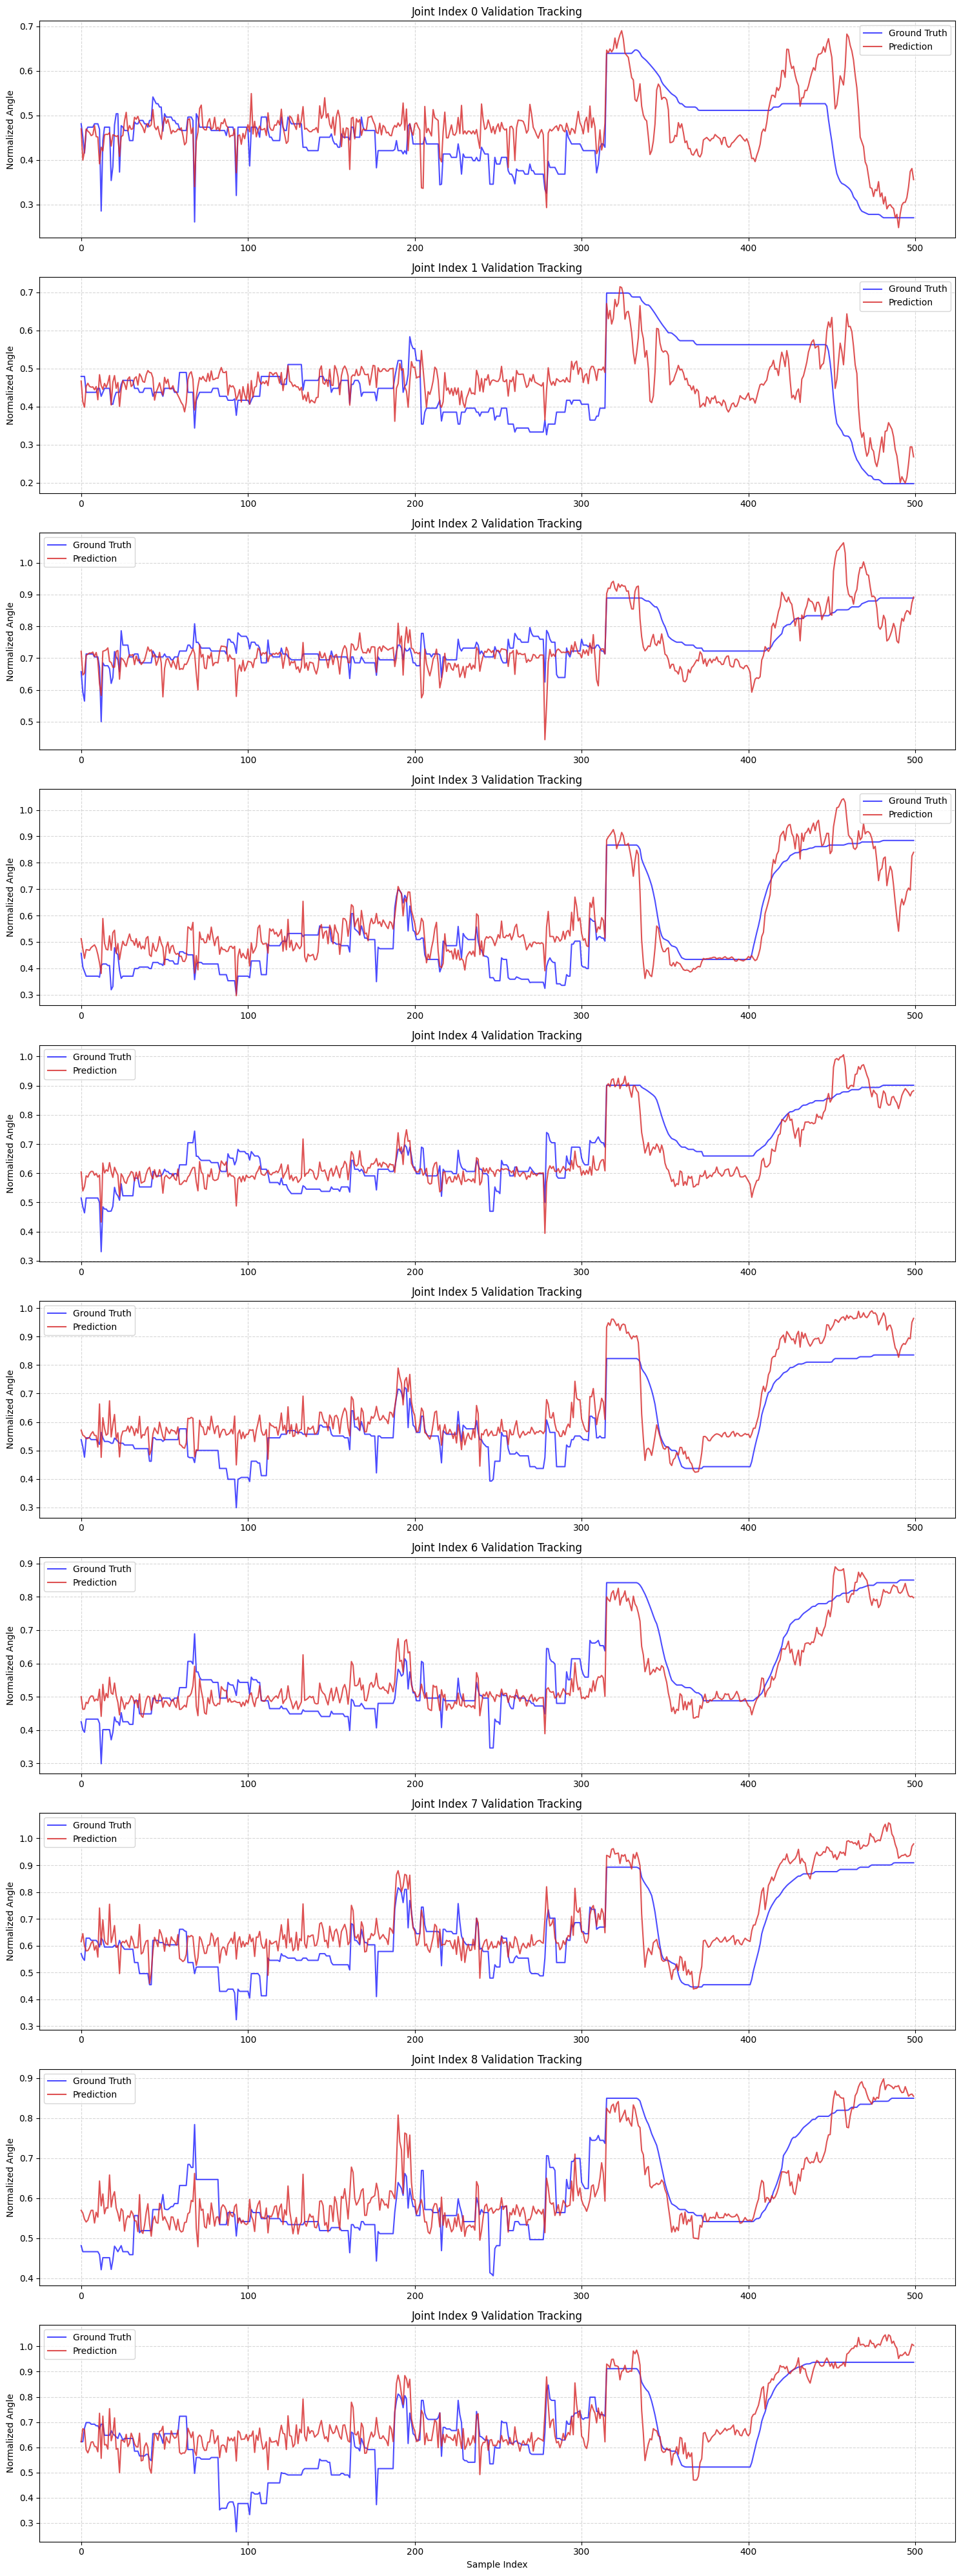

In [20]:
def visualize_validation(model, loader, device, num_samples=400, joint_indices=[0, 1, 2]):
    """
    Plots predictions vs ground truth for a subset of the validation data.
    
    :param num_samples: How many time steps to plot (e.g., 400 = 20 seconds at stride 50)
    :param joint_indices: List of joint indices to plot (e.g., [0,1,2] for Thumb/Index)
    """
    model.eval()
    all_preds = []
    all_targets = []
    
    print("Running inference on validation set...")
    
    with torch.no_grad():
        # Iterate through the loader
        # Note: We unpack 3 items because we updated the Dataset class earlier
        for batch_sEMG, batch_angles, _ in loader: 
            batch_sEMG = batch_sEMG.to(device)
            batch_angles = batch_angles.to(device)
            
            # Forward Pass
            outputs = model(batch_sEMG)
            
            # Save to list
            all_preds.append(outputs.cpu().numpy())
            all_targets.append(batch_angles.cpu().numpy())
            
            # Stop early if we have enough data for the plot
            current_count = sum(len(x) for x in all_preds)
            if current_count >= num_samples:
                break
    
    # Concatenate and slice to exact number of samples
    preds = np.concatenate(all_preds, axis=0)[:num_samples]
    targets = np.concatenate(all_targets, axis=0)[:num_samples]
    
    # --- PLOTTING ---
    num_plots = 10 #len(joint_indices)
    plt.figure(figsize=(15, 4 * num_plots))
    
    # for i, joint_idx in enumerate(joint_indices):
    for i in range (10):
        plt.subplot(num_plots, 1, i + 1)
        
        # Plot Ground Truth (Black)
        plt.plot(targets[:, i], label='Ground Truth', color='blue', alpha=0.7, linewidth=1.5)
        
        # Plot Prediction (Red)
        plt.plot(preds[:, i], label='Prediction', color='#d62728', alpha=0.8, linewidth=1.5)
        
        plt.title(f"Joint Index {i} Validation Tracking")
        plt.ylabel("Normalized Angle")
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.5)

    plt.xlabel("Sample Index")
    plt.tight_layout()
    plt.savefig("Comparison.png", dpi = 600)
    plt.show()

# --- RUN IT ---
# Plot the first 3 joints (Thumb Rotate, Thumb Flex, Index Flex) for 500 samples
visualize_validation(model, test_loader, device, num_samples=500, joint_indices=[0, 1, 2])

## Apply Kalman Filter

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define the Kalman Filter Class ---
class KalmanSmoother:
    def __init__(self, process_noise=1e-4, measurement_noise=0.05, initial_value=0.0):
        self.Q = process_noise   # "Q": Higher = faster reaction, more noise
        self.R = measurement_noise # "R": Higher = smoother line, more lag
        self.P = 1.0             # Initial uncertainty
        self.x = initial_value   # Initial state estimate
        
    def update(self, measurement):
        # Prediction step
        self.P = self.P + self.Q
        
        # Correction step
        K = self.P / (self.P + self.R) # Kalman Gain
        self.x = self.x + K * (measurement - self.x)
        self.P = (1 - K) * self.P
        return self.x

def apply_kalman_smoothing(predictions, Q=1e-4, R=0.05):
    """Applies smoothing to all joints (columns) in the prediction array"""
    num_samples, num_joints = predictions.shape
    smoothed_preds = np.zeros_like(predictions)
    
    for j in range(num_joints):
        kf = KalmanSmoother(process_noise=Q, measurement_noise=R, initial_value=predictions[0, j])
        for i in range(num_samples):
            smoothed_preds[i, j] = kf.update(predictions[i, j])
            
    return smoothed_preds

# --- 2. Generate Predictions (Using your Validation Loader) ---
# We need to run the model to get 'preds' and 'targets' first
model.eval()
all_preds, all_targets = [], []
num_samples_to_plot = 500

print("Generating predictions...")
with torch.no_grad():
    for batch_sEMG, batch_angles, _ in test_loader:
        batch_sEMG = batch_sEMG.to(device)
        outputs = model(batch_sEMG)
        
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(batch_angles.cpu().numpy())
        
        # Stop once we have enough data
        if sum(len(x) for x in all_preds) >= num_samples_to_plot:
            break

# Flatten the lists into numpy arrays
preds = np.concatenate(all_preds, axis=0)[:num_samples_to_plot]
targets = np.concatenate(all_targets, axis=0)[:num_samples_to_plot]

Generating predictions...


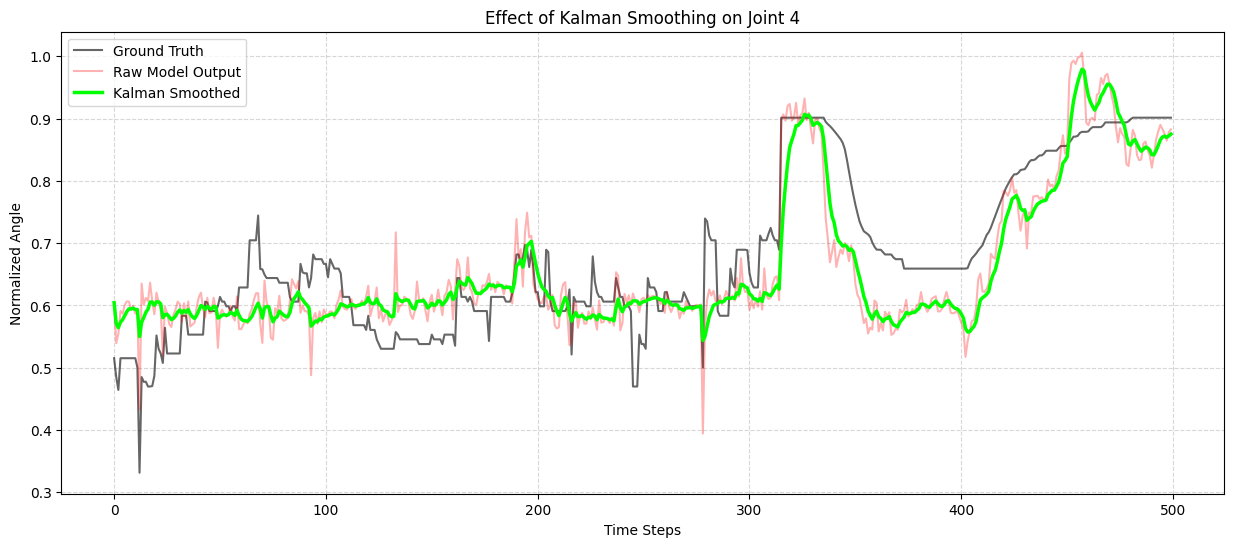

In [23]:
# --- 3. Apply the Smoothing ---
# Adjust Q and R here to tune the smoothness!
# Q=1e-5 makes it very smooth but laggy. Q=1e-3 makes it responsive.
preds_smooth = apply_kalman_smoothing(preds, Q=1e-3, R=0.01)

# --- 4. Plot the Comparison ---
plt.figure(figsize=(15, 6))
joint_idx = 4 # Plotting the Thumb (change to 1 or 2 for other fingers)

# Plot Ground Truth
plt.plot(targets[:, joint_idx], label='Ground Truth', color='black', alpha=0.6, linewidth=1.5)

# Plot Raw Prediction (Noisy)
plt.plot(preds[:, joint_idx], label='Raw Model Output', color='red', alpha=0.3)

# Plot Kalman Smoothed (Clean)
plt.plot(preds_smooth[:, joint_idx], label='Kalman Smoothed', color='lime', linewidth=2.5)

plt.title(f"Effect of Kalman Smoothing on Joint {joint_idx}")
plt.ylabel("Normalized Angle")
plt.xlabel("Time Steps")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("Kalman_for_Joint_4.png", dpi = 300)
plt.show()

In [ ]:
import time
import torch

# Get first batch safely
batch = next(iter(train_loader))
inputs = batch[0]   # input tensor
labels = batch[1]   # ground truth (optional)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
inputs = inputs.to(device)

model.eval()
with torch.no_grad():
    _ = model(inputs)  # warm-up

torch.cuda.synchronize() if device.type == "cuda" else None
start = time.time()
with torch.no_grad():
    outputs = model(inputs)
torch.cuda.synchronize() if device.type == "cuda" else None
end = time.time()

print(f"Inference time: {(end - start)*1000:.3f} ms")


In [ ]:
# --------------------------------------------------------------
# AFTER TRAINING – Convert to static INT8
# --------------------------------------------------------------
print("Converting QAT model to static INT8...")
model.eval()                     # required for conversion
model = model.cpu()              # move QAT model (with fake quants) to CPU
torch.cuda.empty_cache()

# Convert
quantized_model = torch.quantization.convert(model.cpu(), inplace=False)

# Move quantized model back to GPU (or keep on CPU for inference)
quantized_model = quantized_model.to(device)

# --------------------------------------------------------------
# VALIDATE THE QUANTIZED MODEL
# --------------------------------------------------------------
quant_val_loss, quant_rmse, quant_r2 = validate(
    quantized_model, test_loader, criterion, device
)
print(f"Quantized Val Loss={quant_val_loss:.4f}, "
      f"RMSE={quant_rmse:.4f}, R2={quant_r2:.4f}")

# Size check
model_size(quantized_model)

# Save
torch.save(
    quantized_model.state_dict(),
    os.path.join(cfg.save_dir, "best_roformer_quantized.pt")
)

In [ ]:
# Add this after the training loop
# After training: Convert to fully quantized model
model.eval()  # Switch to eval for conversion
quantized_model = torch.quantization.convert(model, inplace=False)

# Optional: Validate the quantized model
quant_val_loss, quant_rmse, quant_r2 = validate(quantized_model, test_loader, criterion, device)
print(f"Quantized Val Loss={quant_val_loss:.4f}, RMSE={quant_rmse:.4f}, R2={quant_r2:.4f}")

# Check quantized size
model_size(quantized_model)

# Save quantized model
torch.save(quantized_model.state_dict(), os.path.join(cfg.save_dir, 'best_roformer_quantized.pt'))

In [ ]:
# Inference Example
model.load_state_dict(torch.load(os.path.join(cfg.save_dir, 'best_roformer.pt')))
model.eval()


In [ ]:

def predict_angles(sEMG_window):  # sEMG_window: [1, 12, 100]
    sEMG_tensor = torch.tensor(sEMG_window, dtype=torch.float32).unsqueeze(0).to(device)
    with torch.no_grad():
        angles = model(sEMG_tensor)
    return angles.cpu().numpy()


In [ ]:
def predict_and_compare(sEMG_window, true_angles):  
    """
    sEMG_window: [12, time_steps] or [1, 12, time_steps]
    true_angles: [num_joints] ground-truth glove values
    """
    # Ensure correct shape: [batch, 12, time_steps]
    if sEMG_window.ndim == 2:   # [12, time_steps]
        sEMG_tensor = torch.tensor(sEMG_window, dtype=torch.float32).unsqueeze(0).to(device)
    elif sEMG_window.ndim == 3: # [1, 12, time_steps]
        sEMG_tensor = torch.tensor(sEMG_window, dtype=torch.float32).to(device)
    else:
        raise ValueError("Unexpected sEMG_window shape")

    with torch.no_grad():
        pred_angles = model(sEMG_tensor)

    pred_angles = pred_angles.cpu().numpy().squeeze()
    true_angles = np.array(true_angles)

    # Print comparison
    print("True angles:      ", np.round(true_angles, 3))
    print("Predicted angles: ", np.round(pred_angles, 3))

    return pred_angles


In [36]:
# Take one batch from DataLoader
for sEMG_batch, angles_batch in train_loader:
    sEMG_sample = sEMG_batch[0].unsqueeze(0).numpy()   # [1, 12, time_steps]
    true_sample = angles_batch[0].numpy()              # [num_joints]
    predict_and_compare(sEMG_sample, true_sample)
    break


ValueError: too many values to unpack (expected 2)

In [22]:
import torch
import torch.nn as nn
import os


def export_fp32_model():
    print("Exporting FP32 model to ONNX...")
    
    # --- 1. Load Configuration ---
    # Use the same config as your training
    cfg = Config() 
    device = torch.device('cpu') # Exporting is best done on CPU
    
    # --- 2. Instantiate the FP32 Model ---
    # Use your original RoFormer, NOT the QuantizedRoFormer
    model = RoFormer(
        num_channels=cfg.num_channels, 
        time_steps=cfg.max_seq_len, 
        num_layers=cfg.num_layers, 
        num_heads=cfg.num_heads, 
        d_model=cfg.d_model, 
        d_ff=cfg.d_ff, 
        num_angles=cfg.num_angles, 
        dropout=cfg.dropout
    )
    
    # --- 3. Load Your Trained Weights ---
    # Load the *best_roformer.pt* file you saved during training
    weights_path = os.path.join(cfg.save_dir, 'best_roformer.pt')
    
    # We must load the state_dict from the *inner* model,
    # since you saved it from the QAT wrapper.
    # If you saved the FP32 model, just use: model.load_state_dict(torch.load(weights_path))
    state_dict = torch.load(weights_path, map_location=device)
    
    # Clean keys if they were saved inside the 'model_fp32.' wrapper
    from collections import OrderedDict
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        if k.startswith('model_fp32.'):
            name = k[11:] # remove `model_fp32.` prefix
            new_state_dict[name] = v
        else:
            new_state_dict[k] = v
            
    model.load_state_dict(new_state_dict, strict = False)
    
    # --- 4. Set to Evaluation Mode ---
    # This is CRITICAL. It disables dropout, etc.
    model.eval()
    
    # --- 5. Create a Dummy Input ---
    # The shape must match your model's forward pass: [batch, channels, time_steps]
    # We use batch_size = 1, as this is typical for real-time inference in Unity.
    dummy_input = torch.randn(1, cfg.num_channels, cfg.max_seq_len, device=device)
    
    # --- 6. Export to ONNX ---
    onnx_file_path = "roformer_model_fp32.onnx"
    
    torch.onnx.export(
        model,
        dummy_input,
        onnx_file_path,
        input_names=['input_emg'],    # Name for Unity to find
        output_names=['output_angles'], # Name for Unity to find
        opset_version=12,             # A good stable version for Unity
        export_params=True,
        do_constant_folding=True
    )
    
    print(f"Successfully exported FP32 model to {onnx_file_path}")

if __name__ == '__main__':
    # (Make sure your model definitions are pasted above)
    export_fp32_model()

Exporting FP32 model to ONNX...
Successfully exported FP32 model to roformer_model_fp32.onnx


/tmp/ipykernel_38/3220433058.py:28: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if seq_len > self.max_seq_len_cached:


## Testing Loaded Model

In [34]:
import torch
import torch.nn as nn
import os
import numpy as np
from collections import OrderedDict


def predict_and_compare(model, device, sEMG_window, true_angles):
    # Ensure correct shape: [batch, 12, time_steps]
    if sEMG_window.ndim == 2:   # [12, time_steps]
        sEMG_tensor = torch.tensor(sEMG_window, dtype=torch.float32).unsqueeze(0).to(device)
    elif sEMG_window.ndim == 3: # [1, 12, time_steps]
        sEMG_tensor = torch.tensor(sEMG_window, dtype=torch.float32).to(device)
    else:
        raise ValueError("Unexpected sEMG_window shape")

    # Run inference
    with torch.no_grad():
        pred_angles = model(sEMG_tensor)

    # Move to CPU and remove batch dimension
    pred_angles = pred_angles.cpu().numpy().squeeze()
    true_angles = np.array(true_angles).squeeze()

    # Print comparison
    print("--- Model Evaluation Check ---")
    print(f"Input Shape: {sEMG_tensor.shape}")
    print(f"Output Shape: {pred_angles.shape}")
    print("------------------------------")
    print("True angles:      ", np.round(true_angles, 3))
    print("Predicted angles: ", np.round(pred_angles, 3))
    print("------------------------------")
    return pred_angles


In [35]:
def evaluate_loaded_model():
    # --- 1. Load Configuration ---
    try:
        cfg = Config()
    except NameError:
        print("ERROR: 'Config' class not defined. Please paste it at the top.")
        return

    device = torch.device('cpu')  # Use CPU for this check

    # --- 2. Instantiate the FP32 Model ---
    try:
        model = RoFormer(
            num_channels=cfg.num_channels,
            time_steps=cfg.max_seq_len,
            num_layers=cfg.num_layers,
            num_heads=cfg.num_heads,
            d_model=cfg.d_model,
            d_ff=cfg.d_ff,
            num_angles=cfg.num_angles,
            dropout=cfg.dropout
        ).to(device)
    except NameError:
        print("ERROR: 'RoFormer' class not defined. Please paste it at the top.")
        return

    # --- 3. Load Your Trained Weights (with Key Cleaning) ---
    weights_path = os.path.join('/kaggle/input/roformer/pytorch/default/1/best_roformer.pt')
    print(f"Loading weights from: {weights_path}")

    try:
        state_dict = torch.load(weights_path, map_location=device)
    except FileNotFoundError:
        print(f"ERROR: Weights file not found at {weights_path}")
        print("Please check your 'cfg.save_dir' path.")
        return

    # Clean keys if they were saved inside the 'model_fp32.' wrapper
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        if k.startswith('model_fp32.'):
            name = k[11:]  # remove `model_fp32.` prefix
            new_state_dict[name] = v
        else:
            new_state_dict[k] = v

    model.load_state_dict(new_state_dict, strict=False)
    print("Successfully loaded and cleaned weights.")

    # --- 4. Set to Evaluation Mode ---
    model.eval()

    # --- 5. Load a Real Data Sample ---
    try:
        # NOTE: You must provide your Dataset/DataLoader logic
        # This is an example, adjust it to match your data pipeline
        # Ensure 'train_dataset' is an instance of 'YourEMGDataset'
        # train_dataset = YourEMGDataset(data_path=..., labels_path=...)
        # train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

        # Get one batch from your DataLoader
        sEMG_batch, angles_batch = next(iter(train_loader))

        # Take the first sample from the batch
        sEMG_sample = sEMG_batch[0].numpy()   # Shape: [12, time_steps]
        true_sample = angles_batch[0].numpy()  # Shape: [num_joints]

    except NameError:
        print("\nERROR: 'train_loader' or 'YourEMGDataset' is not defined.")
        print("Please paste your Dataset/DataLoader code at the top to run the comparison.")
        print("\n--- Evaluation check skipped. ---")
        return
    except Exception as e:
        print(f"\nERROR: Failed to load data from DataLoader: {e}")
        print("Please check your data loading pipeline.")
        print("\n--- Evaluation check skipped. ---")
        return

    # --- 6. Predict and Compare ---
    predict_and_compare(model, device, sEMG_sample, true_sample)


if __name__ == '__main__':
    evaluate_loaded_model()


Loading weights from: /kaggle/input/roformer/pytorch/default/1/best_roformer.pt
ERROR: Weights file not found at /kaggle/input/roformer/pytorch/default/1/best_roformer.pt
Please check your 'cfg.save_dir' path.


# Pipeline for Unity

In [36]:
import torch
import numpy as np
import json
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import r2_score, mean_squared_error

Load Model Weights

In [20]:
checkpoint_path = "/kaggle/input/roformer/pytorch/default/2/42ep_unquantized_0.685.pt"

# Instantiate base model
model = RoFormer(
    cfg.num_channels,
    cfg.max_seq_len,
    cfg.num_layers,
    cfg.num_heads,
    cfg.d_model,
    cfg.d_ff,
    cfg.num_angles,
    cfg.dropout
).to(device)

# Load checkpoint
state_dict = torch.load(checkpoint_path, map_location=device)

# Remove 'module.' prefix
new_state_dict = {}
for k, v in state_dict.items():
    new_state_dict[k.replace("module.", "")] = v

# Load weights
model.load_state_dict(new_state_dict)

# Wrap AFTER loading
if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs!")
    model = torch.nn.DataParallel(model)

model = model.to(device)
model.eval()


Using 2 GPUs!


DataParallel(
  (module): RoFormer(
    (conv1d): Conv1d(12, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (rope): RotaryEmbedding()
    (layers): ModuleList(
      (0): RoFormerLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
        (activation): ReLU()
      )
    )
    (fc): Linear(in_features=128, out_features=10, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

In [31]:

# --- 4. Main Processing Function ---
def process_dataset_for_oneSubject_test(subject, window_size=400, stride=50, mu=255):
    print(f"Processing subject: {subject}")
    
    # Update path to match your environment
    base_path = f'/kaggle/input/ninapro-db2/{subject}/{subject}/*.mat' 
    data_paths = sorted(glob.glob(base_path))
    
    emg_all, glove_all, restim_all = [], [], []
    
    # Load first 2 sessions (E1, E2)
    for path in data_paths[:2]:  
        data = scio.loadmat(path)
        emg_all.append(data['emg'])
        glove_all.append(data['glove'])
        restim_all.append(data['restimulus']) 
    
    # Stack data vertically to form a continuous timeline
    emg = np.vstack(emg_all).astype(np.float32)
    glove = np.vstack(glove_all).astype(np.float32)
    restimulus = np.vstack(restim_all).astype(np.int32).squeeze()

    # ---------------- SIGNAL PROCESSING ----------------
    
    # 1. Bandpass (5-500Hz)
    emg = bandpass_butterworth(emg)
    emg = abs(emg)

    # 4. Normalization (Mu-Law)
    emg = emg / (np.max(np.abs(emg), axis=0, keepdims=True) + 1e-8)
    emg = mu_law_normalize(emg, mu=mu)

    # ---------------- GLOVE PROCESSING ----------------
    
    # 1. Min-Max Normalization [0, 1]
    glove_min = np.min(glove, axis=0, keepdims=True)
    glove_max = np.max(glove, axis=0, keepdims=True)
    glove = (glove - glove_min) / (glove_max - glove_min + 1e-8)

    # 2. Select only the 10 fingers of interest
    cols = [1, 2, 4, 5, 7, 8, 11, 12, 15, 16]
    glove = glove[:, cols]
    glove_min = glove_min[:, cols]
    glove_max = glove_max[:, cols]    


    # ---------------- WINDOWING ----------------
    # This creates the "Sequential" chunks
    
    emg_windows, glove_windows, restim_windows = [], [], []
    
    # Iterate with overlap (stride)
    for i in range(0, len(emg) - window_size, stride):
        # Input: 400ms window
        emg_win = emg[i:i+window_size, :]
        glove_win = glove[i+window_size-1, :]        
        restim_win = restimulus[i+window_size-1]
        
        emg_windows.append(emg_win)
        glove_windows.append(glove_win)
        restim_windows.append(restim_win)

    # Convert to Numpy Arrays
    emg_windows = np.array(emg_windows)
    glove_windows = np.array(glove_windows)
    restim_windows = np.array(restim_windows)

    # ---------------- SAVING ----------------
    output_dir = f"/kaggle/working/db2_pipeline/{subject}"
    os.makedirs(output_dir, exist_ok=True)
    save_path = f"{output_dir}/data.npz"
    np.savez(save_path, 
             sEMG=emg_windows, 
             angles=glove_windows, 
             restim=restim_windows)
             
    print(f"Saved {emg_windows.shape[0]} samples to {save_path}")

# --- Usage Example ---
subjects = ['DB2_s1'] 
for sub in subjects:
    process_dataset_for_oneSubject_test(sub)

Processing subject: DB2_s1
Saved 87225 samples to /kaggle/working/db2_pipeline/DB2_s1/data.npz


In [32]:
# 1. Helper to read Min/Max from JSONL
def get_scaling_params(jsonl_path, subject_id):
    with open(jsonl_path, 'r') as f:
        for line in f:
            entry = json.loads(line)
            if entry['patient_number'] == subject_id:
                # Convert to numpy arrays for easy broadcasting
                min_vals = np.array(entry['min_values'], dtype=np.float32)
                max_vals = np.array(entry['max_values'], dtype=np.float32)
                return min_vals, max_vals
    raise ValueError(f"Subject {subject_id} not found in {jsonl_path}")

# 2. Evaluation Dataset (Strictly Sequential, No Shuffling)
class SequentialEvalDataset(Dataset):
    def __init__(self, npz_path):
        # Load the file created by your preprocessing script
        data = np.load("/kaggle/working/db2_pipeline/DB2_s1/data.npz", mmap_mode='r')
        
        # Load all data directly (No balancing, no shuffling)
        self.sEMG = data['sEMG']     # Shape: (N, 400, 12)
        self.angles = data['angles'] # Shape: (N, 10)
        
        # We assume the preprocessing saved them in time-order
        
    def __len__(self):
        return len(self.sEMG)

    def __getitem__(self, idx):
        # Transpose sEMG to [Channels, Time] for your RoFormer
        sEMG = torch.tensor(self.sEMG[idx].T, dtype=torch.float32)
        target = torch.tensor(self.angles[idx], dtype=torch.float32)
        return sEMG, target

In [34]:
def evaluate_subject(subject_id, model, device, jsonl_path, processed_dir):
    print(f"--- Evaluating Subject {subject_id} ---")
    
    # 1. Setup Paths & Params
    npz_path = f"{processed_dir}/{subject_id}/data.npz"
    min_vals, max_vals = get_scaling_params(jsonl_path, subject_id)
    print(min_vals, max_vals)
    
    # 2. Load Data
    dataset = SequentialEvalDataset(npz_path)
    loader = DataLoader(dataset, batch_size=32, shuffle=False) # Shuffle=False is CRITICAL
    
    # 3. Inference Loop
    model.eval()
    all_preds = []
    all_targets = []
    i=0
    with torch.no_grad():
        for sEMG, target in loader:
            sEMG = sEMG.to(device)
            
            # Forward pass
            output = model(sEMG)
            
            # Store results (still normalized)
            all_preds.append(output.cpu().numpy())
            all_targets.append(target.numpy())
            i+=1
            if(i>5):break
            
    # Concatenate
    preds_norm = np.vstack(all_preds)
    targets_norm = np.vstack(all_targets)
    
    # 4. Un-normalize (Back to Degrees)
    # Formula: x_orig = x_norm * (max - min) + min
    # We use broadcasting: (N, 10) * (10,) + (10,)
    diff = max_vals - min_vals
    
    preds_deg = preds_norm * diff + min_vals
    targets_deg = targets_norm * diff + min_vals
    
    # 5. Metrics
    mse = mean_squared_error(targets_deg, preds_deg)
    rmse = np.sqrt(mse)
    r2 = r2_score(targets_deg, preds_deg)
    
    print(f"Results for Subject {subject_id}:")
    print(f"  RMSE: {rmse:.4f} degrees")
    print(f"  R2 Score: {r2:.4f}")
    
    return targets_deg, preds_deg

--- Evaluating Subject 1 ---
[-41.43892  -38.004795 -25.831825 -22.392052 -27.264063 -44.533894
 -33.17075  -17.829218 -27.456064 -26.391592] [ 69.342514  70.41899   73.27429  102.168236 105.04684  156.21822
 124.60772  106.87225  100.224236  90.33339 ]
Results for Subject 1:
  RMSE: 17.2972 degrees
  R2 Score: -0.9059


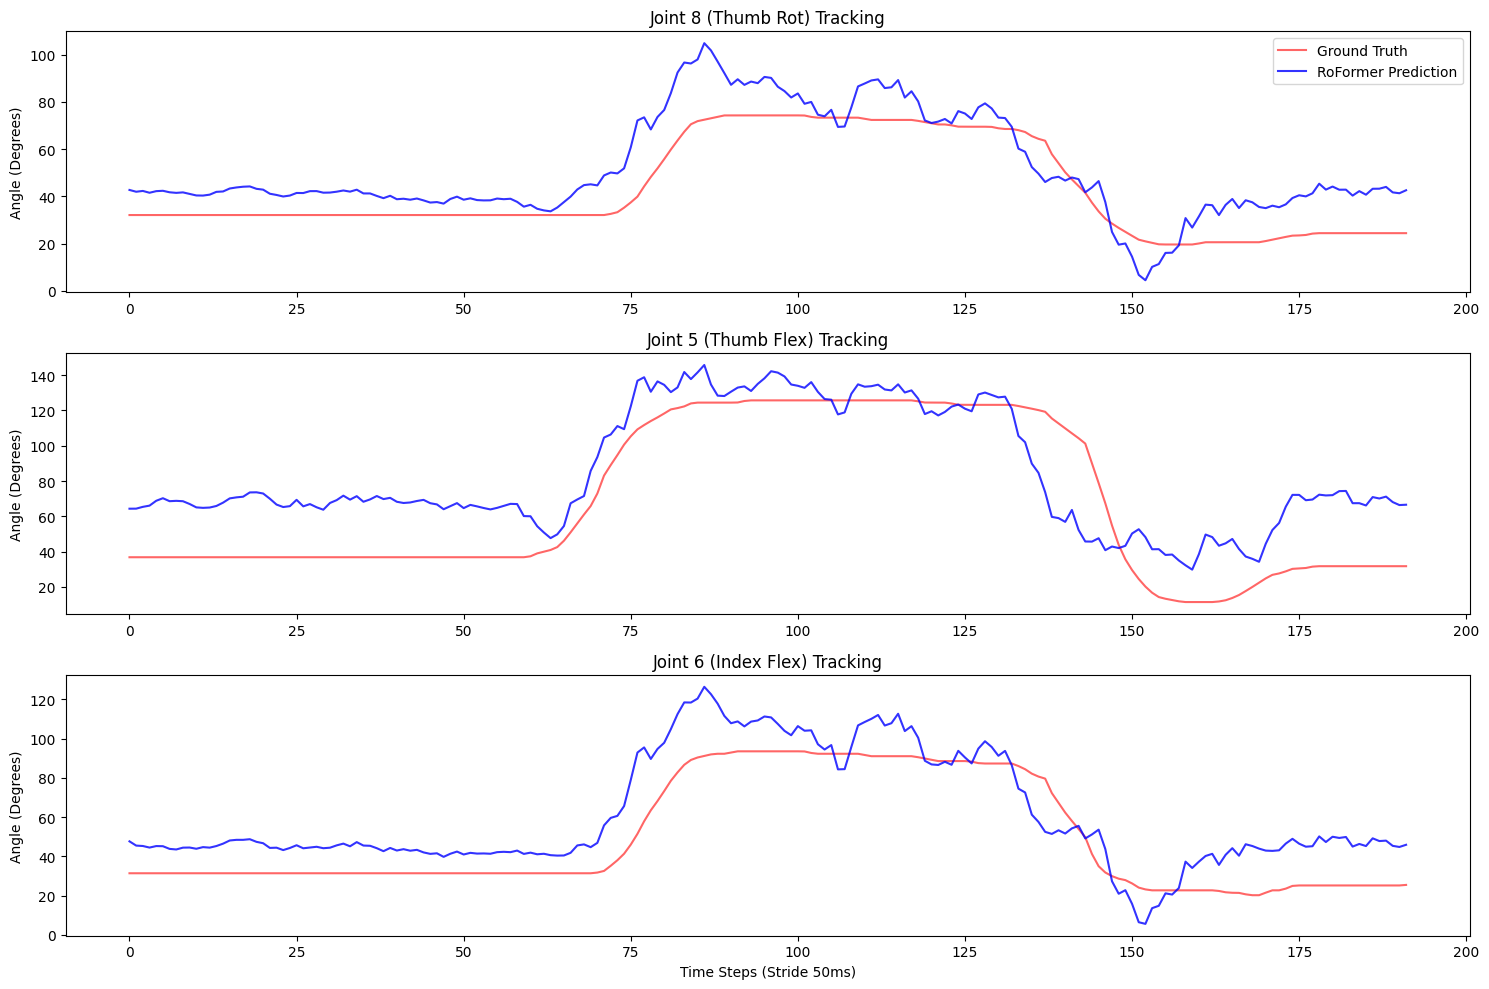

In [37]:
# --- RUN THE EVALUATION ---
# Assuming 'model' is loaded and 'device' is defined
subject_id = 1 # Or whatever string/int id you use, e.g., "DB2_s1"
jsonl_file = "/kaggle/input/ninapro-db2/subject_joint_ranges.jsonl" # Path to your JSONL
proc_dir = "/kaggle/working/db2_pipeline"

targets, preds = evaluate_subject(subject_id, model, device, jsonl_file, proc_dir)

# --- PLOTTING ---
# Let's plot the first 1000 samples (approx 25-50 seconds depending on stride)
# to see the fine-grained movement.
time_steps = np.arange(len(targets))
samples_to_plot = 1000 

# Create a plot for 3 random joints (e.g., Thumb, Index, Middle)
joints_to_plot = [8, 5, 6] # Indices 0, 1, 2 corresponding to first 3 cols in your JSON
joint_names = ["Thumb Rot", "Thumb Flex", "Index Flex"] # Example names

plt.figure(figsize=(15, 10))

for i, joint_idx in enumerate(joints_to_plot):
    plt.subplot(3, 1, i+1)
    
    # Plot Actual
    plt.plot(targets[:samples_to_plot, joint_idx], 
             label='Ground Truth', color='red', alpha=0.6, linewidth=1.5)
    
    # Plot Predicted
    plt.plot(preds[:samples_to_plot, joint_idx], 
             label='RoFormer Prediction', color='blue', alpha=0.8, linewidth=1.5)
    
    plt.title(f"Joint {joint_idx} ({joint_names[i]}) Tracking")
    plt.ylabel("Angle (Degrees)")
    if i == 0: plt.legend()

plt.xlabel("Time Steps (Stride 50ms)")
plt.tight_layout()
plt.show()